# Task 1 — Exploratory Data Analysis on Retail Sales Data
**Track:** Data Analytics · Level 1  
**Goal:** Explore a retail sales dataset to uncover sales patterns, customer behaviour and actionable business insights.

**Dataset:** `retail_sales_data.csv` — 3,893 transactions (Jan 2023 – Dec 2024) with customer demographics, product details, discounts and region. *(Synthetic dataset created for this analysis; the same code works on any retail dataset with similar columns.)*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

## 1. Load Data & Initial Inspection

In [2]:
df = pd.read_csv("retail_sales_data.csv", parse_dates=["date"])
print("Shape:", df.shape)
print("\nDtypes:"); print(df.dtypes)
print("\nNull values:"); print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.head()

Shape: (3893, 13)

Dtypes:
transaction_id               int64
date                datetime64[ns]
customer_id                 object
gender                      object
age                          int64
product_category            object
product_name                object
quantity                     int64
price_per_unit             float64
discount_pct                 int64
total_amount               float64
region                      object
payment_method              object
dtype: object

Null values:
transaction_id      0
date                0
customer_id         0
gender              0
age                 0
product_category    0
product_name        0
quantity            0
price_per_unit      0
discount_pct        0
total_amount        0
region              0
payment_method      0
dtype: int64

Duplicate rows: 0


,transaction_id,date,customer_id,gender,age,product_category,product_name,quantity,price_per_unit,discount_pct,total_amount,region,payment_method
0,1,2023-01-01,C1525,Female,60,Sports,Running Shoes,1,95.0,20,76.00,South,Credit Card
1,2,2023-01-01,C1646,Female,44,Home & Kitchen,Coffee Maker,5,90.0,0,450.00,West,Credit Card
2,3,2023-01-01,C1772,Male,20,Beauty,Skincare Kit,4,45.0,0,180.00,South,Credit Card
3,4,2023-01-01,C1595,Female,33,Clothing,Sneakers,4,80.0,20,256.00,North,Credit Card
4,5,2023-01-01,C1207,Female,39,Clothing,T-Shirt,1,25.0,5,23.75,East,Cash


### Observations
- The dataset has **3,893 rows and 13 columns**, covering two full years.
- There are **no null values and no duplicate rows**, so no cleaning is needed before analysis.
- `date` was parsed as `datetime64`; `customer_id` and the categorical columns are text. Total revenue across the period is **851,471** (currency units).

## 2. Descriptive Statistics

In [3]:
num_cols = ["age", "quantity", "price_per_unit", "discount_pct", "total_amount"]
stats = df[num_cols].agg(["mean", "median", "std"]).T
stats["mode"] = df[num_cols].mode().iloc[0]
stats.round(2)

,mean,median,std,mode
age,37.24,36.0,11.82,18.0
quantity,2.02,2.0,1.18,1.0
price_per_unit,157.51,80.0,204.93,120.0
discount_pct,7.77,5.0,9.43,0.0
total_amount,218.72,144.0,217.75,120.0


### Observations
- **Average transaction value is 219** but the median is only **144**: the mean is pulled up by a few high-priced purchases (laptops, smartphones), so the distribution is **right-skewed**. The std (218) is nearly as large as the mean.
- The most common quantity per order is **1** (mean 2.02), and the most common discount is **0%**: customers mostly pay full price.
- Average customer age is **37** (median 36); the age distribution is roughly symmetric.

## 3. Time Series Analysis

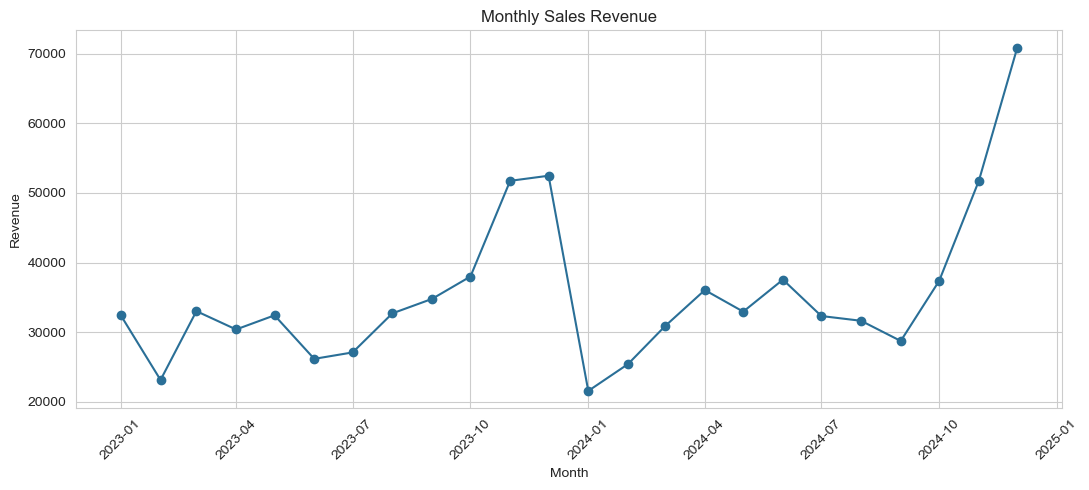

In [4]:
monthly = df.groupby(df["date"].dt.to_period("M"))["total_amount"].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(11, 5))
plt.plot(monthly.index, monthly.values, marker="o", color="#2a6f97")
plt.title("Monthly Sales Revenue")
plt.xlabel("Month"); plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

### Observation (monthly)
Sales are **strongly seasonal**: revenue jumps in **November and December** in both years, peaking at about **70.9k in Dec 2024**, versus a typical 21–38k in other months. January and February are the weakest months (post-holiday slump).

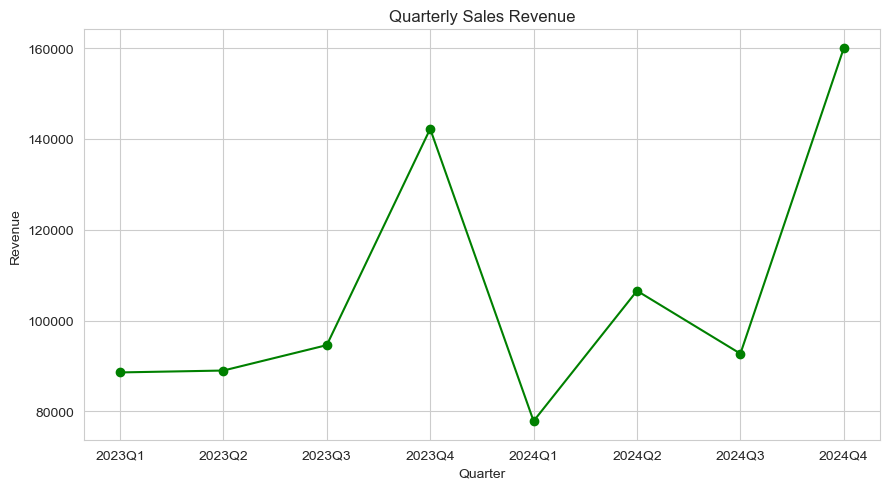

In [24]:
quarterly = df.groupby(df["date"].dt.to_period("Q"))["total_amount"].sum()
quarterly.index = quarterly.index.astype(str)

plt.figure(figsize=(9, 5))
plt.plot(quarterly.index, quarterly.values, marker="o", color="green")
plt.title("Quarterly Sales Revenue")
plt.xlabel("Quarter"); plt.ylabel("Revenue")
plt.tight_layout(); plt.show()

### Observation (quarterly)
- **Q4 accounts for 35%** of all revenue in the two years, versus the 25% you would expect if sales were even.
- Total revenue grew from **414,352 (2023)** to **437,118 (2024)**, a modest **5.5%**. Growth came mainly from Q2 and Q4 2024, while Q1 2024 was *weaker* than Q1 2023.

## 4. Customer Demographics

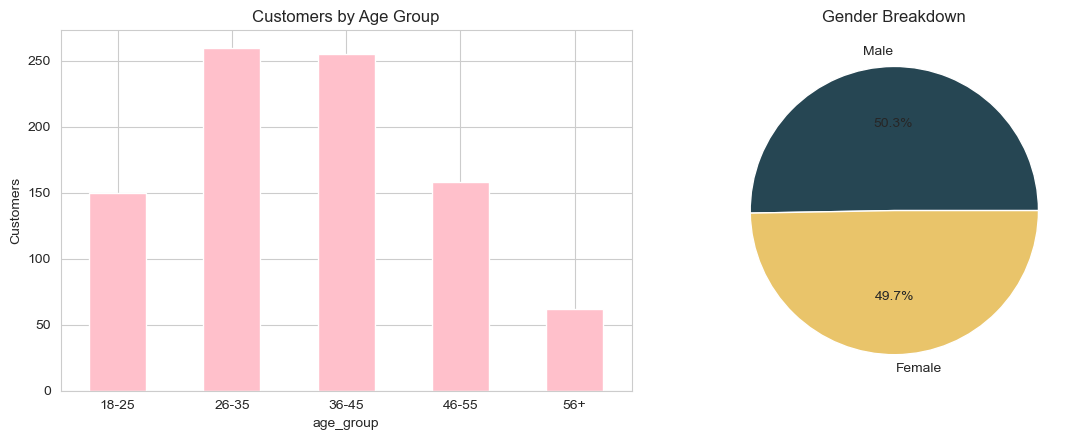

Unique customers: 885


In [23]:
customers = df.drop_duplicates("customer_id").copy()
customers["age_group"] = pd.cut(customers["age"], bins=[17, 25, 35, 45, 55, 100],
                                labels=["18-25", "26-35", "36-45", "46-55", "56+"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
customers["age_group"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="pink")
ax[0].set_title("Customers by Age Group"); ax[0].set_ylabel("Customers"); ax[0].tick_params(axis="x", rotation=0)
customers["gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[1], colors=["#264653", "#e9c46a"])
ax[1].set_title("Gender Breakdown"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
print("Unique customers:", len(customers))

### Observations
- The customer base (**885 unique customers**) is concentrated in the **26–45** age bands, which together make up about 58% of customers. The 56+ group is the smallest (~7%).
- Gender is almost perfectly balanced (~50% male, ~50% female), so neither gender dominates the base.

In [7]:
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", "56+"])
spend = df.groupby("age_group", observed=True)["total_amount"].agg(["sum", "mean"]).round(1)
spend.columns = ["Total revenue", "Avg transaction"]
spend

,Total revenue,Avg transaction
age_group,,
18-25,140035.0,209.3
26-35,257883.0,219.3
36-45,237512.0,224.3
46-55,161970.5,228.4
56+,54070.5,193.1


**Observation:** The 26–35 and 36–45 groups generate the most revenue overall simply because there are more of them. Average transaction value is similar across groups (about 190–230), so growth lies in customer *volume* by age group rather than in higher spend per purchase.

## 5. Product Analysis

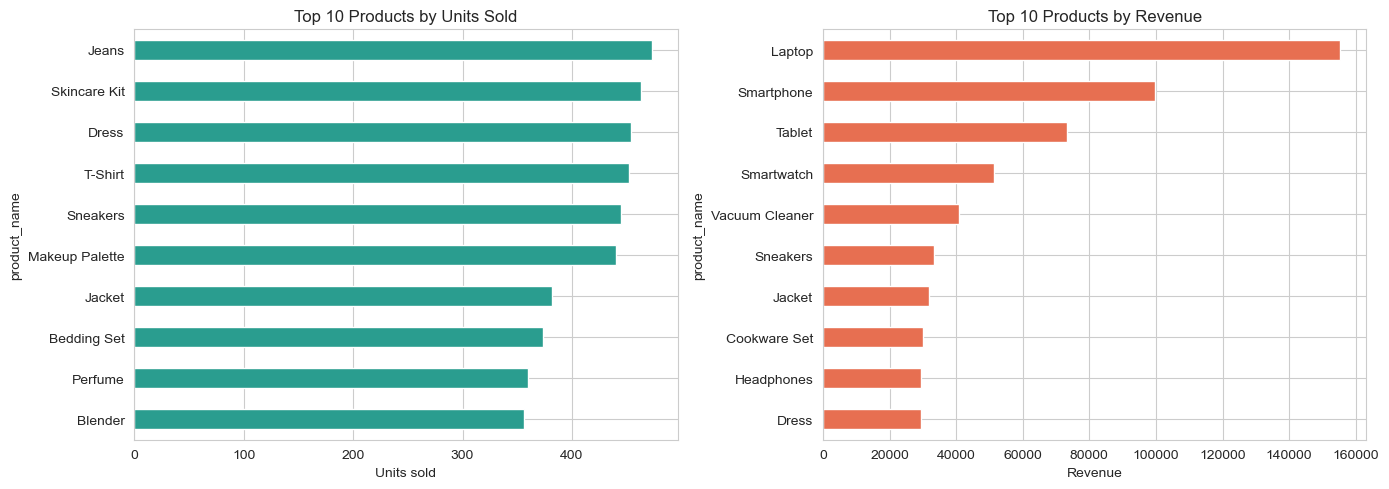

In [21]:
top_units = df.groupby("product_name")["quantity"].sum().nlargest(10)
top_rev = df.groupby("product_name")["total_amount"].sum().nlargest(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top_units.sort_values().plot(kind="barh", ax=ax[0], color="#2a9d8f")
ax[0].set_title("Top 10 Products by Units Sold"); ax[0].set_xlabel("Units sold")
top_rev.sort_values().plot(kind="barh", ax=ax[1], color="#e76f51")
ax[1].set_title("Top 10 Products by Revenue"); ax[1].set_xlabel("Revenue")
plt.tight_layout(); plt.show()

### Observations
- The **best-selling products by units** are low-priced items: Jeans, Skincare Kit, Dress, T-Shirt and Sneakers (each ~445–475 units).
- The **top products by revenue** are an entirely different list: **Laptop (~155k)** and **Smartphone (~100k)** lead, followed by Tablet and Smartwatch.
- Best-sellers by volume are not the best earners: only Sneakers, Jacket and Dress appear in both top-10 lists.

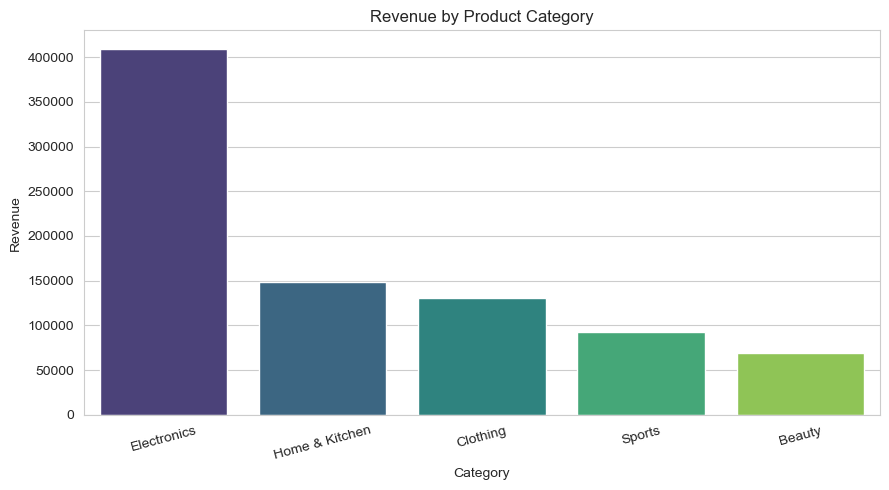

,revenue,units,revenue_share_%,unit_share_%
product_category,,,,
Electronics,409403.50,1057,48.1,13.5
Home & Kitchen,148873.50,1554,17.5,19.8
Clothing,130818.25,2206,15.4,28.1
Sports,92956.25,1420,10.9,18.1
Beauty,69419.50,1611,8.2,20.5


In [9]:
cat_rev = df.groupby("product_category")["total_amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=cat_rev.index, y=cat_rev.values, palette="viridis", hue=cat_rev.index, legend=False)
plt.title("Revenue by Product Category")
plt.xlabel("Category"); plt.ylabel("Revenue")
plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

cat_summary = df.groupby("product_category").agg(revenue=("total_amount", "sum"), units=("quantity", "sum"))
cat_summary["revenue_share_%"] = (cat_summary["revenue"] / cat_summary["revenue"].sum() * 100).round(1)
cat_summary["unit_share_%"] = (cat_summary["units"] / cat_summary["units"].sum() * 100).round(1)
cat_summary.sort_values("revenue", ascending=False)

### Observation
**Electronics** earns **48% of revenue from only 13% of units sold**, while **Clothing** sells 28% of all units but earns just 15% of revenue. Beauty is the smallest category by revenue. Electronics is clearly the profit engine, and Clothing is the traffic driver.

## 6. Correlation Heatmap

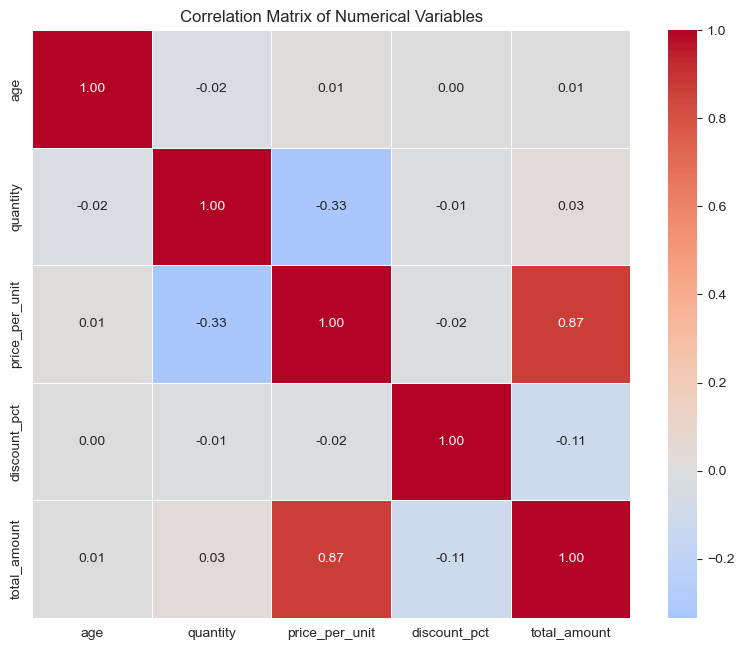

In [20]:
plt.figure(figsize=(8, 6.6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f", linewidths=.5)
plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout(); plt.show()

### Observations
- `total_amount` is very strongly correlated with `price_per_unit` (**r ≈ 0.87**): revenue is driven by *what* is bought, not by how many units.
- `quantity` and `price_per_unit` are **negatively correlated (≈ -0.33)**: customers buy several cheap items but usually only one expensive item.
- `discount_pct` has a weak **negative** correlation with `total_amount` (≈ -0.11) and essentially **none with quantity** (≈ -0.01). This is explored further below.
- Age is uncorrelated with every numeric variable, so age affects *what* people buy, not *how much* they spend.

## 7. Additional Visualisations — Non-Obvious Insights

### 7a. Do discounts actually increase quantity sold?

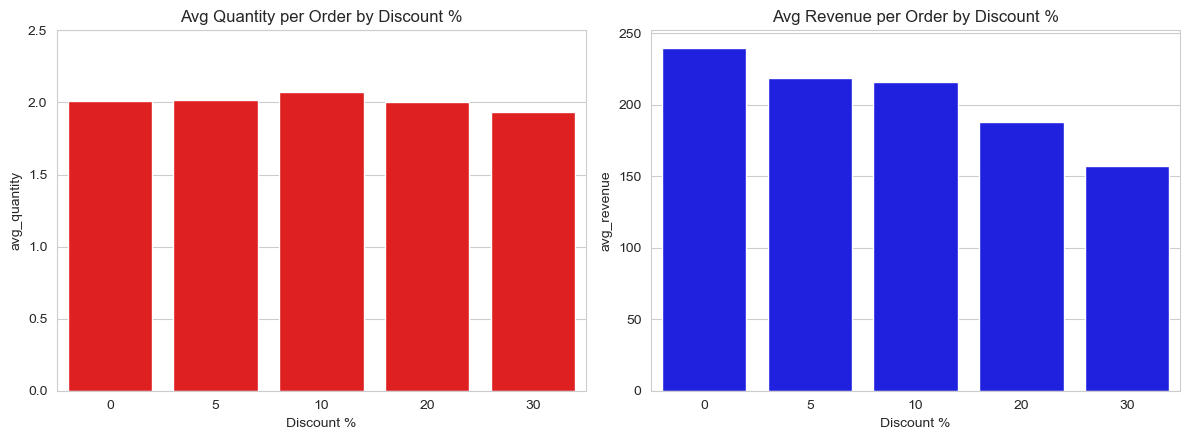

Gross sales: 921,835 | Discounts given: 70,364 (7.6% of gross)


In [16]:
disc = df.groupby("discount_pct").agg(avg_quantity=("quantity", "mean"),
                                     avg_revenue=("total_amount", "mean"),
                                     transactions=("transaction_id", "count"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=disc.index, y=disc["avg_quantity"], ax=ax[0], color="red")
ax[0].set_title("Avg Quantity per Order by Discount %"); ax[0].set_xlabel("Discount %"); ax[0].set_ylim(0, 2.5)
sns.barplot(x=disc.index, y=disc["avg_revenue"], ax=ax[1], color="blue")
ax[1].set_title("Avg Revenue per Order by Discount %"); ax[1].set_xlabel("Discount %")
plt.tight_layout(); plt.show()
disc.round(2)

gross = (df["quantity"] * df["price_per_unit"]).sum()
given = gross - df["total_amount"].sum()
print(f"Gross sales: {gross:,.0f} | Discounts given: {given:,.0f} ({given/gross*100:.1f}% of gross)")

### Observation: discounts are not paying for themselves
Average quantity per order stays at **about 2.0 whether the discount is 0% or 30%**. Discounts do not make customers buy more. Revenue per order falls from **240 (no discount) to 157 (30% off), a 34% drop**. In total, discounts cost **70,364 (7.6% of gross sales)** without a visible volume gain.

> *Caveat:* this is an observational comparison, and discounts might attract customers who would otherwise not purchase at all. An A/B test would be needed to confirm.

### 7b. What does each age group buy?

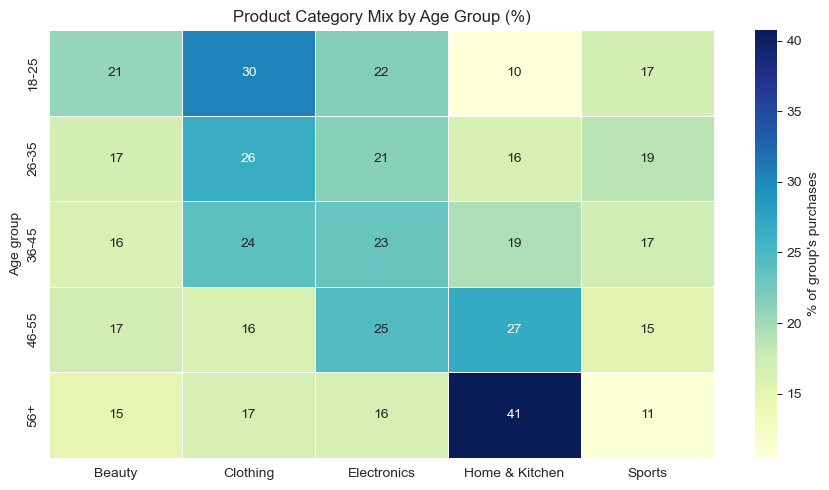

In [12]:
mix = pd.crosstab(df["age_group"], df["product_category"], normalize="index") * 100

plt.figure(figsize=(9, 5))
sns.heatmap(mix, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=.5, cbar_kws={"label": "% of group's purchases"})
plt.title("Product Category Mix by Age Group (%)")
plt.ylabel("Age group"); plt.xlabel("")
plt.tight_layout(); plt.show()

### Observation
Preferences differ sharply with age: **Clothing is ~30% of purchases for ages 18–25** but only ~16% for ages 46–55, while **Home & Kitchen rises from ~10% (18–25) to ~41% (56+)**. Age doesn't change spend per purchase, but it clearly changes *what* each group buys, so marketing messages should be targeted by age group.

### 7c. Which days drive sales?

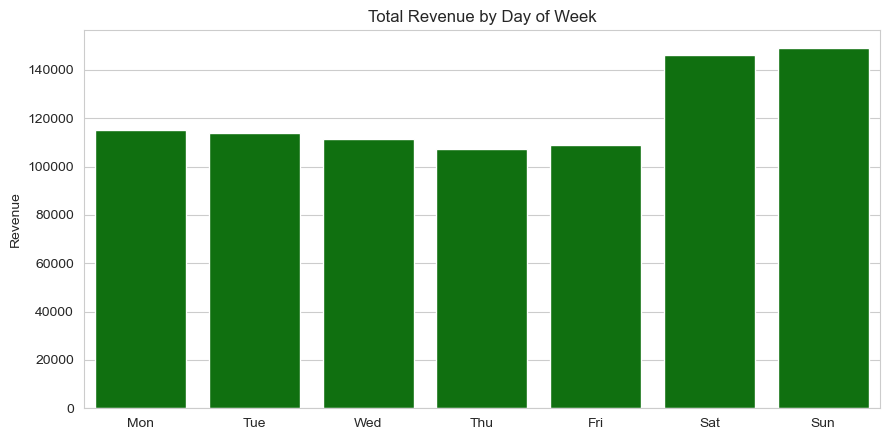

In [14]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday = df.groupby(df["date"].dt.dayofweek)["total_amount"].sum()
weekday.index = days

plt.figure(figsize=(9, 4.5))
sns.barplot(x=weekday.index, y=weekday.values, color="green")
plt.title("Total Revenue by Day of Week"); plt.ylabel("Revenue"); plt.xlabel("")
plt.tight_layout(); plt.show()

In [25]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this directory:")
print(os.listdir())

Current working directory:
C:\Users\Lenovo\OIBSIP\DataAnalytics-L1-EDARetailSales

Files in this directory:
['.ipynb_checkpoints', 'README.md', 'retail_sales_data.csv', 'Task1_EDA_Retail_Sales.ipynb']


### Observation
Saturday and Sunday generate **35% of revenue from just 2 of 7 days** (29% of the week), roughly **30% more per day** than any weekday. Weekends are the key trading window.

## Conclusion & Business Recommendations

**Summary:** Sales are highly seasonal (Q4 = 35% of revenue) and concentrated on weekends. Electronics generates nearly half of all revenue, volume leaders and revenue leaders are different products, and discounting is not lifting order size.

### Recommendations
1. **Cut blanket discounts, especially 20–30% deals.** Discounts cost 7.6% of gross sales, and average quantity does not rise with discount level. Replace deep discounts with targeted offers (bundles, loyalty points) and test them with an A/B experiment.
2. **Build the Q4 and weekend plan early.** Q4 earns 35% of revenue and weekends 35%. Stock up on Electronics before October, schedule extra staff and ad spend for Nov–Dec and weekends, and run a January campaign to lift the post-holiday slump.
3. **Use Clothing as the traffic driver and cross-sell Electronics.** Clothing brings the most transactions (high volume, low price), while Electronics brings the revenue. Promote Electronics accessories (headphones, smartwatches) to Clothing buyers.
4. **Target by age group.** Promote Clothing and Beauty to 18–35 and Home & Kitchen to 46+. Since spend per order is similar across ages, the gain comes from relevance, not from price changes.
5. **Protect top customers.** The top 10% of customers generate **25% of revenue**, so a loyalty programme for them is a cheap way to protect revenue.

**Limitations:** the data covers only two years and does not include cost or margin, so "revenue" is not "profit". All findings are associations, not proven causes.